# TV4 — Tuần 1: Dataset, Loss & Training Engine

Notebook kiểm tra **Step 6 của tuần 1**: CacheDataset → augmentation 3D → ba mô hình TV3 + FiLM → Deep Supervision Dice+BCE → AdamW + warmup/cosine → best checkpoint.

**Dữ liệu giả chỉ phục vụ kiểm tra code.** Loss/Dice trong notebook không phải kết quả thực nghiệm của đồ án. Chưa bao gồm TTA, hậu xử lý hoặc benchmark các tuần sau.

Chọn kernel `.venv` của repo và **Run All**. Notebook mặc định chạy CPU với 12 ca nhỏ, hai epoch cho từng kiến trúc thật M1/M2/M3.

## 1. Chuẩn bị môi trường

Tại root repo: cài PyTorch phù hợp phần cứng, rồi `pip install -r requirements.txt`.

Trên Colab, chạy trước trong một cell riêng:
```python
!git clone https://github.com/ngmhoang62/CS406-SCB-TumorSeg.git
%cd /content/CS406-SCB-TumorSeg
# Nếu dùng bản notebook này từ máy, upload các module TV4 vào clone trước.
%pip install -r requirements.txt
```
Không clone lại nếu đã có repo. Các file TV4 hiện được tạo cục bộ; URL main chỉ có chúng sau khi bạn đưa code lên GitHub.

In [1]:
import gc
import json
import random
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/models/factory.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook bên trong repo CS406-SCB-TumorSeg")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import monai
from IPython.display import display
from monai.utils import set_determinism
from scripts.generate_synthetic_tv4 import generate_synthetic_tv4
from src.datasets import MAMA_MIA_Dataset, build_loaders
from src.losses import DiceBCELoss
from src.engine import Trainer, LinearWarmupCosineAnnealingLR
from src.models import build_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_determinism(seed=SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Root:", ROOT)
print("Python:", sys.version.split()[0], "Torch:", torch.__version__, "MONAI:", monai.__version__)
print("Device:", DEVICE)

Root: C:\Users\LENOVO\OneDrive\Documents\CS406.R12-xulianhvaungdung\CS406-SCB-TumorSeg
Python: 3.12.14 Torch: 2.5.1+cpu MONAI: 1.4.0
Device: cpu


## 2. Cấu hình

`SMOKE_TEST=True`: patch `32×32×64`, CNN channels nhỏ, Swin feature size 12. M3 có downsampling 32 lần và InstanceNorm: `32³` tạo bottleneck `1³` gây lỗi, nên trục W được giữ ở 64.

Để train dữ liệu thật: đặt cả `SMOKE_TEST=False` và `USE_SYNTHETIC=False`, kiểm tra đường dẫn bên dưới. Khi đó dùng patch `96³`, 120 epoch, warmup 5 và bề rộng mô hình gốc.

In [2]:
SMOKE_TEST = True
USE_SYNTHETIC = True
IP_MODE = "IP3_multi"  # IP1_post1 | IP2_sub | IP3_multi
USE_FILM = True
ARCHITECTURES = ["M1", "M2", "M3"]
PATCH_SIZE = (32, 32, 64) if SMOKE_TEST else (96, 96, 96)
EPOCHS = 2 if SMOKE_TEST else 120
WARMUP_EPOCHS = 1 if SMOKE_TEST else 5
BATCH_SIZE = 2 if SMOKE_TEST else 16
CNN_CHANNELS = (4, 8, 16, 24, 32) if SMOKE_TEST else (32, 64, 128, 256, 320)
SWIN_FEATURE_SIZE = 12 if SMOKE_TEST else 48
LR, WEIGHT_DECAY = 3e-4, 1e-5
OUT_DIR = ROOT / "outputs/tv4_week1"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if USE_SYNTHETIC:
    NPZ_DIR, METADATA_CSV = generate_synthetic_tv4(
        ROOT / "data/synthetic_tv4", shape=PATCH_SIZE, seed=SEED)
else:
    NPZ_DIR = ROOT / "data/processed/npz_96x96x96"
    METADATA_CSV = ROOT / "data/splits/splits_metadata.csv"
print("Synthetic:", USE_SYNTHETIC, "Patch:", PATCH_SIZE, "Epochs:", EPOCHS)
print("NPZ:", NPZ_DIR)

Synthetic: True Patch: (32, 32, 64) Epochs: 2
NPZ: C:\Users\LENOVO\OneDrive\Documents\CS406.R12-xulianhvaungdung\CS406-SCB-TumorSeg\data\synthetic_tv4\npz


## 3. Kiểm tra data contract và ba IP modes

Fake NPZ giữ đúng 4 keys của nhóm: `image`, `mask`, `auto_mask`, `subtype_id`; kích thước giảm chỉ dành cho smoke test. Kênh 3 giả lập tương phản, **không phải PE+CLAHE thật**. Split test không tham gia training/chọn checkpoint.

In [3]:
metadata = pd.read_csv(METADATA_CSV)
display(pd.crosstab(metadata["split"], metadata["tumor_subtype"]))
assert not metadata.patient_id.duplicated().any()
first_path = NPZ_DIR / f"{metadata.iloc[0].patient_id}.npz"
with np.load(first_path, allow_pickle=False) as sample:
    assert set(sample.files) == {"image", "mask", "auto_mask", "subtype_id"}
    assert sample["image"].dtype == np.float16
    assert sample["mask"].dtype == np.uint8
    assert sample["subtype_id"].dtype == np.int64
    print({k: (sample[k].shape, str(sample[k].dtype)) for k in sample.files})

for mode, expected_channels in [("IP1_post1", 1), ("IP2_sub", 1), ("IP3_multi", 3)]:
    dataset = MAMA_MIA_Dataset(METADATA_CSV, NPZ_DIR, "val", mode)
    item = dataset[0]
    assert item["image"].shape[0] == expected_channels
    assert item["mask"].shape[0] == 1
    assert item["subtype_id"].dtype == torch.long
    print(mode, tuple(item["image"].shape), "OK")
del dataset, item

tumor_subtype,HER2-enriched,HER2-pure,Luminal,Triple Negative
split,,,,
test,1,1,1,1
train,1,1,1,1
val,1,1,1,1


{'image': ((3, 32, 32, 64), 'float16'), 'mask': ((1, 32, 32, 64), 'uint8'), 'auto_mask': ((1, 32, 32, 64), 'uint8'), 'subtype_id': ((), 'int64')}
IP1_post1 (1, 32, 32, 64) OK
IP2_sub (1, 32, 32, 64) OK
IP3_multi (3, 32, 32, 64) OK


## 4. CacheDataset và augmentation 3D

Đọc NPZ vào RAM trước; các phép random chạy sau cache. Flip/rotation được áp dụng đồng thời lên ảnh và nhãn, scale intensity chỉ áp dụng lên ảnh. Validation giữ nguyên toàn VOI, batch=1 để hỗ trợ ca có kích thước khác nhau. `num_workers=0` thuận tiện trên Windows/Jupyter.

In [4]:
loaders = build_loaders(METADATA_CSV, NPZ_DIR, ip_mode=IP_MODE,
                        batch_size=BATCH_SIZE, patch_size=PATCH_SIZE,
                        cache_rate=1.0, num_workers=0, seed=SEED)
batch = next(iter(loaders["train"]))
assert batch["image"].shape[2:] == PATCH_SIZE
assert batch["mask"].shape[2:] == PATCH_SIZE
assert torch.isfinite(batch["image"]).all()
assert set(torch.unique(batch["mask"]).tolist()) <= {0.0, 1.0}
print("Train batch:", tuple(batch["image"].shape), tuple(batch["mask"].shape))
print("Subtype ids:", batch["subtype_id"].tolist())

Train batch:

 (2, 3, 32, 32, 64) (2, 1, 32, 32, 64)
Subtype ids: [0, 2]


## 5. Tích hợp mô hình TV3 và training thật 2 epoch

Loss = `1.0·(Dice+BCE)full + 0.5·(Dice+BCE)half + 0.25·(Dice+BCE)quarter`.
Nhãn phụ được resize bằng nearest neighbour; model trả **logits**, loss tự sigmoid. Mỗi mô hình được giải phóng trước khi tạo mô hình tiếp theo.

Trên CUDA hỗ trợ bf16: AMP bf16, không cần GradScaler. Trên CPU: fp32. Cell kiểm tra các head, backward/gradient FiLM, trọng số thực sự thay đổi, CSV log và reload best checkpoint. Không yêu cầu Dice cao hoặc loss giảm đơn điệu trên fake data.

In [5]:
all_histories = {}
summary = []
for arch in ARCHITECTURES:
    print(f"\n--- {arch} | {IP_MODE} | FiLM={USE_FILM} ---", flush=True)
    torch.manual_seed(SEED)
    model = build_model(arch, ip_mode=IP_MODE, use_film=USE_FILM,
                        deep_supervision=True, resunet_channels=CNN_CHANNELS,
                        swin_feature_size=SWIN_FEATURE_SIZE,
                        swin_use_checkpoint=False if SMOKE_TEST else True).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    criterion = DiceBCELoss(weights=(1.0, 0.5, 0.25))
    scheduler = LinearWarmupCosineAnnealingLR(optimizer, WARMUP_EPOCHS, EPOCHS)
    trainer = Trainer(model, optimizer, criterion, scheduler, device=DEVICE, use_amp=True)
    print("Precision:", "bf16 AMP" if trainer.amp_enabled else "fp32", flush=True)

    # Test all three supervision heads and FiLM gradient before the two-epoch run.
    model.train()
    x = batch["image"].to(DEVICE)
    y = batch["mask"].to(DEVICE)
    subtype = batch["subtype_id"].to(DEVICE)
    with torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=trainer.amp_enabled):
        heads = model(x, subtype=subtype)
        assert len(heads) == 3
        assert [tuple(h.shape[2:]) for h in heads] == [
            PATCH_SIZE, tuple(s // 2 for s in PATCH_SIZE), tuple(s // 4 for s in PATCH_SIZE)]
        check_loss = criterion(heads, y)
    check_loss.backward()
    film_grad = sum(p.grad.detach().float().abs().sum().item()
                    for name, p in model.named_parameters()
                    if "film_generator" in name and p.grad is not None)
    if USE_FILM:
        assert film_grad > 0, "FiLM không nhận gradient"
    optimizer.zero_grad(set_to_none=True)
    del heads, check_loss
    before = next(model.parameters()).detach().clone()
    config = {"arch": arch, "ip_mode": IP_MODE, "use_film": USE_FILM,
              "synthetic": USE_SYNTHETIC, "smoke_test": SMOKE_TEST,
              "patch_size": list(PATCH_SIZE), "cnn_channels": list(CNN_CHANNELS),
              "swin_feature_size": SWIN_FEATURE_SIZE, "seed": SEED}
    history = trainer.fit(loaders["train"], loaders["val"], EPOCHS,
                          OUT_DIR / arch, run_config=config)
    assert len(history) == EPOCHS
    assert np.isfinite(history.select_dtypes("number").to_numpy()).all()
    assert not torch.equal(before, next(model.parameters()).detach())
    checkpoint = torch.load(OUT_DIR / arch / "best.pt", map_location=DEVICE, weights_only=True)
    assert 1 <= checkpoint["epoch"] <= EPOCHS
    assert checkpoint["val_dice"] == history.val_dice.max()
    model.load_state_dict(checkpoint["model"], strict=True)
    model.eval()
    with torch.no_grad():
        output = model(x, subtype=subtype)
    assert output.shape == y.shape and torch.isfinite(output).all()
    all_histories[arch] = history
    summary.append({"arch": arch, "epochs": len(history),
                    "best_val_dice": float(history.val_dice.max()),
                    "film_grad_L1": film_grad, "bf16_amp": trainer.amp_enabled,
                    "synthetic": USE_SYNTHETIC, "status": "PASS"})
    del output, before, checkpoint, model, optimizer, scheduler, trainer, x, y, subtype
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summary)
summary_df.to_csv(OUT_DIR / "smoke_summary.csv", index=False)
(OUT_DIR / "smoke_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
display(summary_df)
assert summary_df.status.eq("PASS").all()
print("PASS: train/backward/deep-supervision/checkpoint cho", ARCHITECTURES)


--- M1 | IP3_multi | FiLM=True ---


Precision: fp32


Epoch 1/2 | train_loss=3.0395 | val_loss=1.7951 | val_dice=0.0301


Epoch 2/2 | train_loss=2.9616 | val_loss=1.7599 | val_dice=0.0373



--- M2 | IP3_multi | FiLM=True ---


Precision: fp32


... (4 outputs left out)

Epoch 1/2 | train_loss=3.0229 | val_loss=1.7234 | val_dice=0.0385


Epoch 2/2 | train_loss=2.7924 | val_loss=1.6154 | val_dice=0.0933


,arch,epochs,best_val_dice,film_grad_L1,bf16_amp,synthetic,status
0,M1,2,0.037321,64.759372,False,True,PASS
1,M2,2,0.052743,69.581458,False,True,PASS
2,M3,2,0.093305,99.147601,False,True,PASS


PASS: train/backward/deep-supervision/checkpoint cho ['M1', 'M2', 'M3']


## 6. Kiểm tra log huấn luyện

Đồ thị dưới đây chỉ kiểm tra lịch sử được ghi đúng. Checkpoint chọn theo Dice của validation, không theo test.

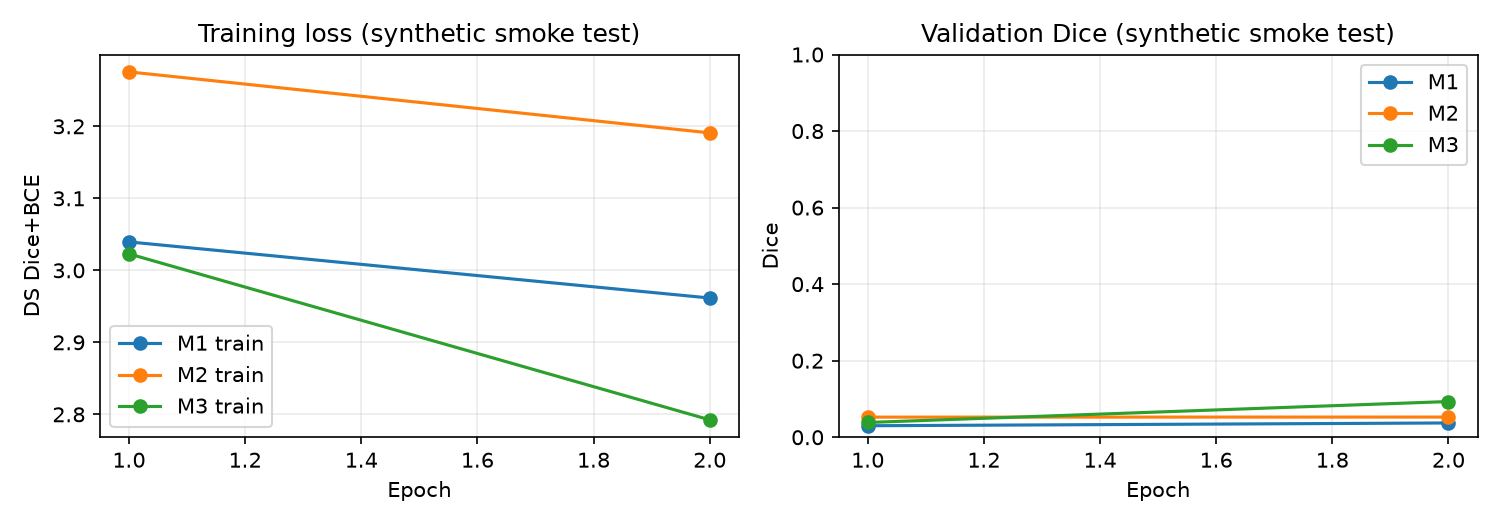

Outputs: C:\Users\LENOVO\OneDrive\Documents\CS406.R12-xulianhvaungdung\CS406-SCB-TumorSeg\outputs\tv4_week1


In [6]:
import matplotlib.pyplot as plt
from IPython.display import Image
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for arch, history in all_histories.items():
    axes[0].plot(history.epoch, history.train_loss, marker="o", label=f"{arch} train")
    axes[1].plot(history.epoch, history.val_dice, marker="o", label=arch)
axes[0].set(title="Training loss (synthetic smoke test)", xlabel="Epoch", ylabel="DS Dice+BCE")
axes[1].set(title="Validation Dice (synthetic smoke test)", xlabel="Epoch", ylabel="Dice", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT_DIR / "training_smoke.png", dpi=150)
display(Image(filename=str(OUT_DIR / "training_smoke.png")))
plt.close(fig)
print("Outputs:", OUT_DIR)

## Hoàn tất phạm vi tuần 1

Nếu cell cuối chạy được, các phần Dataset/DataLoader, loss, training engine và tích hợp với model TV3 đã qua smoke test. Các file nguồn nằm trong `src/datasets`, `src/losses`, `src/engine`; hướng dẫn chi tiết tại `docs/tv4_week1.md`.

CPU smoke test chưa xác nhận VRAM, tốc độ, AMP bf16 trên A100 hoặc hiệu quả trên MRI thật. Các phần tuần 2 trở đi chưa được triển khai ở đây.